In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [17]:
df = pd.read_csv("/home/patel-krish/anaconda3/BrainyBeam/heart.csv")
df = df.drop_duplicates().dropna().reset_index(drop=True)

target_column = "target"

X_df = pd.get_dummies(
    df.drop(columns=[target_column]), dtype=float
)

X_all = X_df.to_numpy(dtype=float)
y_raw = df[target_column].to_numpy()

if not np.isfinite(X_all).all():
    raise ValueError("Features contain invalid values.")

classes = np.unique(y_raw)

if len(classes) != 2:
    raise ValueError("This comparison requires a binary target.")

y_all = (y_raw == classes[1]).astype(int)

rng = np.random.default_rng(42)
train_idx, val_idx, test_idx = [], [], []

for cls in [0, 1]:
    idx = rng.permutation(np.where(y_all == cls)[0])

    if len(idx) < 5:
        raise ValueError("Too few observations in a class.")

    n_test = max(1, int(round(0.20 * len(idx))))
    n_val = max(1, int(round(0.20 * len(idx))))

    test_idx.extend(idx[:n_test])
    val_idx.extend(idx[n_test:n_test + n_val])
    train_idx.extend(idx[n_test + n_val:])

train_idx = rng.permutation(train_idx)
val_idx = rng.permutation(val_idx)
test_idx = rng.permutation(test_idx)

X_train_raw, X_val_raw, X_test_raw = (
    X_all[train_idx], X_all[val_idx], X_all[test_idx]
)

y_train, y_val, y_test = (
    y_all[train_idx], y_all[val_idx], y_all[test_idx]
)

# Fit scaling on training data only.
mean = X_train_raw.mean(axis=0)
std = X_train_raw.std(axis=0)
std[std == 0] = 1.0

X_train = (X_train_raw - mean) / std
X_val = (X_val_raw - mean) / std
X_test = (X_test_raw - mean) / std

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)
print("Original target labels:", classes)

Train: (180, 13)
Validation: (61, 13)
Test: (61, 13)
Original target labels: [0 1]


In [18]:


def metrics(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))

    accuracy = (tp + tn) / len(y_true)

    precision_pos = tp / (tp + fp) if tp + fp else 0
    recall_pos = tp / (tp + fn) if tp + fn else 0

    precision_neg = tn / (tn + fn) if tn + fn else 0
    recall_neg = tn / (tn + fp) if tn + fp else 0

    f1_pos = (
        2 * precision_pos * recall_pos /
        (precision_pos + recall_pos)
        if precision_pos + recall_pos else 0
    )

    f1_neg = (
        2 * precision_neg * recall_neg /
        (precision_neg + recall_neg)
        if precision_neg + recall_neg else 0
    )

    return {
        "Accuracy": accuracy,
        "Precision": precision_pos,
        "Recall": recall_pos,
        "F1": f1_pos,
        "Macro_F1": (f1_pos + f1_neg) / 2,
        "TP": int(tp),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn)
    }


def show_confusion_matrix(y_true, y_pred, title):
    cm = np.zeros((2, 2), dtype=int)

    for actual, predicted in zip(y_true, y_pred):
        cm[actual, predicted] += 1

    print(f"\n{title} confusion matrix:")
    print(pd.DataFrame(
        cm,
        index=["Actual 0", "Actual 1"],
        columns=["Predicted 0", "Predicted 1"]
    ))

    return cm

In [19]:


def sigmoid(z):
    z = np.clip(z, -40, 40)
    return 1 / (1 + np.exp(-z))


def train_logistic(X, y, lr=0.05, epochs=800, l2=0.001):
    y = y.reshape(-1, 1)
    n, features = X.shape

    w = np.zeros((features, 1))
    b = 0.0

    for _ in range(epochs):
        p = sigmoid(X @ w + b)

        dw = X.T @ (p - y) / n + l2 * w
        db = np.mean(p - y)

        w -= lr * dw
        b -= lr * db

    return w, b


def predict_logistic(model, X):
    w, b = model
    return (sigmoid(X @ w + b).ravel() >= 0.5).astype(int)


logistic_model = train_logistic(X_train, y_train)

In [20]:


def predict_knn(X_ref, y_ref, X_query, k=5, exclude_self=False):
    predictions = []

    for i, row in enumerate(X_query):
        distances = np.sqrt(np.sum((X_ref - row) ** 2, axis=1))

        if exclude_self:
            distances[i] = np.inf

        nearest = np.argsort(distances, kind="stable")[:k]
        labels = y_ref[nearest]

        zeros = np.sum(labels == 0)
        ones = np.sum(labels == 1)

        if zeros == ones:
            prediction = labels[0]
        else:
            prediction = int(ones > zeros)

        predictions.append(prediction)

    return np.array(predictions)


knn_model = {"k": 5}

In [21]:


def train_svm(X, y, lr=0.005, epochs=1200, C=1.0):
    y_signed = np.where(y == 1, 1.0, -1.0)
    n, features = X.shape

    w = np.zeros(features)
    b = 0.0

    for _ in range(epochs):
        margins = y_signed * (X @ w + b)
        active = margins < 1

        dw = w.copy()
        db = 0.0

        if np.any(active):
            dw -= C * (
                X[active].T @ y_signed[active]
            ) / n

            db = -C * np.sum(y_signed[active]) / n

        w -= lr * dw
        b -= lr * db

    return w, b


def predict_svm(model, X):
    w, b = model
    return ((X @ w + b) >= 0).astype(int)


svm_model = train_svm(X_train, y_train)




In [32]:


def gini(y):
    if len(y) == 0:
        return 0

    p = np.mean(y == 1)
    return 1 - p**2 - (1 - p)**2


def build_tree(X, y, depth=0, max_depth=5, min_samples=5):
    node = {
        "prediction": int(np.mean(y) >= 0.5),
        "feature": None,
        "threshold": None,
        "left": None,
        "right": None
    }

    if (
        depth >= max_depth
        or len(y) < 2 * min_samples
        or len(np.unique(y)) == 1
    ):
        return node

    parent_gini = gini(y)
    best_gain = 0
    best_split = None

    for feature in range(X.shape[1]):
        values = np.unique(X[:, feature])

        if len(values) < 2:
            continue

        thresholds = (values[:-1] + values[1:]) / 2

        if len(thresholds) > 25:
            positions = np.linspace(
                0, len(thresholds) - 1, 25, dtype=int
            )
            thresholds = thresholds[positions]

        for threshold in thresholds:
            left = X[:, feature] <= threshold
            right = ~left

            if (
                left.sum() < min_samples
                or right.sum() < min_samples
            ):
                continue

            weighted_gini = (
                left.sum() * gini(y[left])
                + right.sum() * gini(y[right])
            ) / len(y)

            gain = parent_gini - weighted_gini

            if gain > best_gain:
                best_gain = gain
                best_split = (feature, threshold, left, right)

    if best_split is None:
        return node

    feature, threshold, left, right = best_split

    node["feature"] = feature
    node["threshold"] = threshold
    node["left"] = build_tree(
        X[left], y[left], depth + 1, max_depth, min_samples
    )
    node["right"] = build_tree(
        X[right], y[right], depth + 1, max_depth, min_samples
    )

    return node


def predict_tree_one(node, row):
    if node["feature"] is None:
        return node["prediction"]

    if row[node["feature"]] <= node["threshold"]:
        return predict_tree_one(node["left"], row)

    return predict_tree_one(node["right"], row)


def predict_tree(tree, X):
    return np.array([
        predict_tree_one(tree, row) for row in X
    ])


tree_model = build_tree(
    X_train, y_train, max_depth=5, min_samples=5
)

In [33]:

def initialize_nn(input_size, hidden1=32, hidden2=16, seed=11):
    rng = np.random.default_rng(seed)

    return {
        "W1": rng.normal(
            0, np.sqrt(2 / input_size), (input_size, hidden1)
        ),
        "b1": np.zeros((1, hidden1)),
        "g1": np.ones((1, hidden1)),
        "be1": np.zeros((1, hidden1)),
        "rm1": np.zeros((1, hidden1)),
        "rv1": np.ones((1, hidden1)),

        "W2": rng.normal(
            0, np.sqrt(2 / hidden1), (hidden1, hidden2)
        ),
        "b2": np.zeros((1, hidden2)),
        "g2": np.ones((1, hidden2)),
        "be2": np.zeros((1, hidden2)),
        "rm2": np.zeros((1, hidden2)),
        "rv2": np.ones((1, hidden2)),

        "W3": rng.normal(
            0, np.sqrt(1 / hidden2), (hidden2, 1)
        ),
        "b3": np.zeros((1, 1))
    }


def bn_forward(z, gamma, beta, rm, rv, training):
    if training:
        mean = z.mean(axis=0, keepdims=True)
        var = z.var(axis=0, keepdims=True)
        inv = 1 / np.sqrt(var + 1e-5)
        xhat = (z - mean) * inv

        rm *= 0.9
        rm += 0.1 * mean
        rv *= 0.9
        rv += 0.1 * var

        cache = (xhat, inv, len(z))
    else:
        xhat = (z - rm) / np.sqrt(rv + 1e-5)
        cache = None

    return gamma * xhat + beta, cache


def bn_backward(dout, cache, gamma):
    xhat, inv, n = cache

    dgamma = np.sum(dout * xhat, axis=0, keepdims=True)
    dbeta = np.sum(dout, axis=0, keepdims=True)
    dxhat = dout * gamma

    dx = inv / n * (
        n * dxhat
        - dxhat.sum(axis=0, keepdims=True)
        - xhat * (dxhat * xhat).sum(axis=0, keepdims=True)
    )

    return dx, dgamma, dbeta


def nn_forward(X, p, training, dropout=0.2, rng=None):
    if rng is None:
        rng = np.random.default_rng(100)

    z1 = X @ p["W1"] + p["b1"]
    n1, c1 = bn_forward(
        z1, p["g1"], p["be1"], p["rm1"], p["rv1"], training
    )

    a1 = np.maximum(n1, 0)

    m1 = (
        (rng.random(a1.shape) >= dropout).astype(float) / (1-dropout)
        if training and dropout > 0 else np.ones_like(a1)
    )
    h1 = a1 * m1

    z2 = h1 @ p["W2"] + p["b2"]
    n2, c2 = bn_forward(
        z2, p["g2"], p["be2"], p["rm2"], p["rv2"], training
    )

    a2 = np.maximum(n2, 0)

    m2 = (
        (rng.random(a2.shape) >= dropout).astype(float) / (1-dropout)
        if training and dropout > 0 else np.ones_like(a2)
    )
    h2 = a2 * m2

    prob = sigmoid(h2 @ p["W3"] + p["b3"])

    cache = (X, n1, h1, m1, c1, n2, h2, m2, c2, prob)
    return prob, cache


def nn_train(X, y, epochs=100, dropout=0.2, lr=0.005, seed=11):
    p = initialize_nn(X.shape[1], seed=seed)
    rng = np.random.default_rng(seed + 1)
    history = {"train_loss": [], "val_loss": []}

    for epoch in range(epochs):
        order = rng.permutation(len(X))

        for start in range(0, len(X), 32):
            idx = order[start:start + 32]

            if len(idx) < 2:
                continue

            xb = X[idx]
            yb = y[idx].reshape(-1, 1)

            prob, cache = nn_forward(
                xb, p, True, dropout=dropout, rng=rng
            )

            Xc, n1, h1, m1, c1, n2, h2, m2, c2, prob = cache
            n = len(xb)

            dz3 = (prob - yb) / n
            dW3 = h2.T @ dz3 + 0.001 * p["W3"]
            db3 = dz3.sum(axis=0, keepdims=True)

            dh2 = dz3 @ p["W3"].T
            dn2 = (dh2 * m2) * (n2 > 0)

            dz2, dg2, dbe2 = bn_backward(dn2, c2, p["g2"])
            dW2 = h1.T @ dz2 + 0.001 * p["W2"]
            db2 = dz2.sum(axis=0, keepdims=True)

            dh1 = dz2 @ p["W2"].T
            dn1 = (dh1 * m1) * (n1 > 0)

            dz1, dg1, dbe1 = bn_backward(dn1, c1, p["g1"])
            dW1 = Xc.T @ dz1 + 0.001 * p["W1"]
            db1 = dz1.sum(axis=0, keepdims=True)

            for name, grad in [
                ("W1", dW1), ("b1", db1),
                ("W2", dW2), ("b2", db2),
                ("W3", dW3), ("b3", db3),
                ("g1", dg1), ("be1", dbe1),
                ("g2", dg2), ("be2", dbe2)
            ]:
                p[name] -= lr * grad

        train_prob, _ = nn_forward(X, p, False, dropout=0)
        eps = 1e-8

        train_loss = -np.mean(
            y * np.log(train_prob.ravel() + eps)
            + (1-y) * np.log(1-train_prob.ravel() + eps)
        )

        history["train_loss"].append(train_loss)

    return p, history


nn_model, nn_history = nn_train(
    X_train, y_train, epochs=100, dropout=0.2
)

In [34]:


def predict_nn(model, X):
    prob, _ = nn_forward(X, model, False, dropout=0)
    return (prob.ravel() >= 0.5).astype(int)


models = {
    "Logistic Regression": {
        "train": predict_logistic(logistic_model, X_train),
        "val": predict_logistic(logistic_model, X_val),
        "test": predict_logistic(logistic_model, X_test)
    },

    "k-NN": {
    
        "train": predict_knn(
            X_train, y_train, X_train, k=5, exclude_self=True
        ),
        "val": predict_knn(X_train, y_train, X_val, k=5),
        "test": predict_knn(X_train, y_train, X_test, k=5)
    },

    "Linear SVM": {
        "train": predict_svm(svm_model, X_train),
        "val": predict_svm(svm_model, X_val),
        "test": predict_svm(svm_model, X_test)
    },

    "Decision Tree": {
        "train": predict_tree(tree_model, X_train),
        "val": predict_tree(tree_model, X_val),
        "test": predict_tree(tree_model, X_test)
    },

    "Deep Neural Network": {
        "train": predict_nn(nn_model, X_train),
        "val": predict_nn(nn_model, X_val),
        "test": predict_nn(nn_model, X_test)
    }
}

In [35]:

records = []

for name, predictions in models.items():
    for split_name, y_true in [
        ("Train", y_train),
        ("Validation", y_val),
        ("Test", y_test)
    ]:
        score = metrics(y_true, predictions[split_name])

        records.append({
            "Model": name,
            "Split": split_name,
            **score
        })

results = pd.DataFrame(records)

print("\nMODEL PERFORMANCE")
print(
    results[
        ["Model", "Split", "Accuracy", "Precision",
         "Recall", "F1", "Macro_F1"]
    ].round(4).to_string(index=False)
)

results.to_csv("traditional_vs_deep_learning_metrics.csv", index=False)

KeyError: 'Train'

In [25]:


overfit_rows = []

for name in models:
    train_score = metrics(y_train, models[name]["train"])
    val_score = metrics(y_val, models[name]["val"])

    overfit_rows.append({
        "Model": name,
        "Train Accuracy": train_score["Accuracy"],
        "Validation Accuracy": val_score["Accuracy"],
        "Accuracy Gap": (
            train_score["Accuracy"] - val_score["Accuracy"]
        ),
        "Train Macro F1": train_score["Macro_F1"],
        "Validation Macro F1": val_score["Macro_F1"],
        "Macro F1 Gap": (
            train_score["Macro_F1"] - val_score["Macro_F1"]
        )
    })

overfit_df = pd.DataFrame(overfit_rows)

print("\nOVERFITTING ANALYSIS")
print(overfit_df.round(4).to_string(index=False))

overfit_df.to_csv("overfitting_analysis.csv", index=False)


OVERFITTING ANALYSIS
              Model  Train Accuracy  Validation Accuracy  Accuracy Gap  Train Macro F1  Validation Macro F1  Macro F1 Gap
Logistic Regression          0.8111               0.8361       -0.0250          0.8082               0.8357       -0.0274
               k-NN          0.7722               0.8361       -0.0638          0.7684               0.8339       -0.0654
         Linear SVM          0.8056               0.8361       -0.0305          0.7988               0.8339       -0.0351
      Decision Tree          0.8611               0.7869        0.0742          0.8595               0.7832        0.0764
Deep Neural Network          0.7444               0.7541       -0.0097          0.7361               0.7473       -0.0112


In [30]:
test_results = results[results["Split"] == "Test"].copy()

metric_names = ["Accuracy", "Precision", "Recall", "F1"]
x = np.arange(len(metric_names))
width = 0.15

plt.figure(figsize=(13, 6))

for i, (_, row) in enumerate(test_results.iterrows()):
    values = [row[m] for m in metric_names]

    plt.bar(
        x + (i - (len(test_results)-1)/2) * width,
        values,
        width=width,
        label=row["Model"]
    )

plt.xticks(x, metric_names)
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.title("Traditional ML vs Deep Learning: Test Performance")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

NameError: name 'results' is not defined

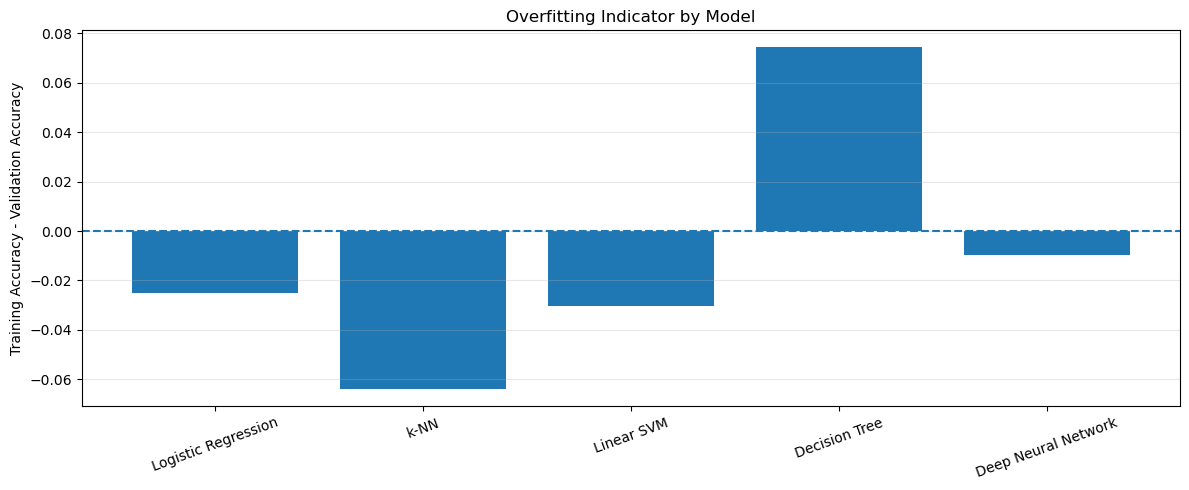

In [27]:


plt.figure(figsize=(12, 5))

plt.bar(
    overfit_df["Model"],
    overfit_df["Accuracy Gap"]
)

plt.axhline(0, linestyle="--")
plt.ylabel("Training Accuracy - Validation Accuracy")
plt.title("Overfitting Indicator by Model")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

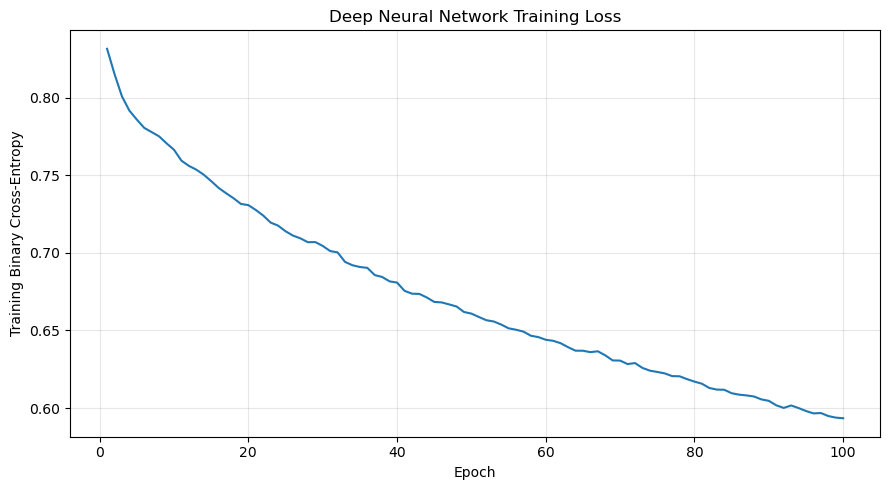

In [28]:


plt.figure(figsize=(9, 5))
plt.plot(
    range(1, len(nn_history["train_loss"]) + 1),
    nn_history["train_loss"]
)

plt.xlabel("Epoch")
plt.ylabel("Training Binary Cross-Entropy")
plt.title("Deep Neural Network Training Loss")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [29]:
for name in models:
    show_confusion_matrix(
        y_test, models[name]["test"], name
    )


Logistic Regression confusion matrix:
          Predicted 0  Predicted 1
Actual 0           23            5
Actual 1            4           29

k-NN confusion matrix:
          Predicted 0  Predicted 1
Actual 0           21            7
Actual 1            2           31

Linear SVM confusion matrix:
          Predicted 0  Predicted 1
Actual 0           20            8
Actual 1            2           31

Decision Tree confusion matrix:
          Predicted 0  Predicted 1
Actual 0           23            5
Actual 1            3           30

Deep Neural Network confusion matrix:
          Predicted 0  Predicted 1
Actual 0           20            8
Actual 1            4           29


In [36]:


best_test = test_results.sort_values(
    "Macro_F1", ascending=False
).iloc[0]

smallest_gap = overfit_df.sort_values(
    "Accuracy Gap", ascending=False
).iloc[-1]

print("\nSUMMARY")
print("Best test Macro F1 model:", best_test["Model"])
print("Test Macro F1:", round(best_test["Macro_F1"], 4))
print("Smallest accuracy gap model:", smallest_gap["Model"])

print("\nSaved:")
print("- traditional_vs_deep_learning_metrics.csv")
print("- overfitting_analysis.csv")

NameError: name 'test_results' is not defined